<a href="https://colab.research.google.com/github/Dunk0725/GIS-26/blob/NJ-Youth-Football-GIS/PS4_Map11_NJ_Youth_Sports_Legislative_Districts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Map 11 — New Jersey Youth-Sports Policy Families by Legislative District
**PS4 | Rutgers–Camden GIS for Public Administration | 222nd NJ Legislature, 2026–2027 session**  
**Legislative research snapshot:** November 12, 2026  
**Researcher-provided dataset:** `NJ_Youth_Sports_District_Summary(1).csv`

### Research question
Where are primary sponsors of youth-sports and interscholastic-athletics policy families distributed among New Jersey's 40 legislative districts?

**Interpretation rule:** The statistic is the **number of unique, qualifying policy families associated with at least one primary sponsor in a district**. It is **not** the count of individual bills or enacted laws. A policy family may legitimately be counted for multiple districts. T1 = community youth sports; T2 = K–12 interscholastic athletics; T3 = adjacent topics (excluded from primary shading).

The 40-district data table below is a *frozen researcher-provided export*, not a live legislative query. The coding and official source links for individual policies remain in the companion legislative inventory. Before submitting PS4, verify legislative statuses and sponsorship against the official bill pages and publish the underlying district CSV to GitHub so your professor can rerun the code straight from the internet.

## 1 · Data and source URLs

- **Legislative boundaries (2023 elections onward)**: NJ Office of GIS (NJOGIS), [`Legislative_Districts_of_NJ_Hosted_3857`](https://services2.arcgis.com/XVOqAjTOJ5P6ngMu/arcgis/rest/services/Legislative_Districts_of_NJ_Hosted_3857/FeatureServer/0). This is the *2023-forward* boundary layer, **not** the old 2011 map.
- **County outlines**: NJ Office of GIS, [`NJ_Counties_3857`](https://services2.arcgis.com/XVOqAjTOJ5P6ngMu/arcgis/rest/services/NJ_Counties_3857/FeatureServer/0).
- **Adopted district plan**: [NJ Apportionment Commission, 2022–2030 adopted map and shapefiles](https://www.apportionmentcommission.org/adoption2022map.asp).
- **Legislative records**: [NJ Legislature bill search](https://www.njleg.gov/bill-search).
- **Dataset provenance**: original researcher-provided `Policy_Families`, `Bill_Records`, `Policy_District_Bridge`, and `District_Summary`, dated November 12, 2026.

The `.csv` used for the join is embedded as text immediately below so this notebook can run even before the researcher publishes it. **For course submission, replace the embedded fallback with your permanent raw GitHub CSV URL using `DISTRICT_SUMMARY_URL`.** If using a related PS4 notebook, do not silently substitute this derived district summary for the original legislative inventory; cite its preparation and your own verification.

In [8]:
# Colab usually includes pandas/matplotlib. Install geospatial packages if missing.
%pip -q install geopandas shapely pyproj requests folium

In [9]:
import io
import pandas as pd

# REPLACE with your actual RAW GitHub URL before submitting PS4.
# Example: https://raw.githubusercontent.com/USERNAME/REPO/main/data/NJ_Youth_Sports_District_Summary.csv
DISTRICT_SUMMARY_URL = "https://raw.githubusercontent.com/Dunk0725/GIS-26/NJ-Youth-Football-GIS/NJ_Youth_Sports_District_Summary.csv"

# Frozen copy of the researcher's November 12, 2026 district-summary export.
# This keeps the current notebook usable before the file is published to GitHub.
EMBEDDED_DISTRICT_SUMMARY_CSV = """Legislative_District,Map11_Policy_Family_Count_T1_T2,T1_Community_Youth_Sports_Count,T2_K12_Interscholastic_Count,T3_Adjacent_Count_Excluded_From_Map11,All_Inventory_Policy_Families,Snapshot_Date
1,4,1,3,0,4,2026-11-12
2,3,2,1,0,3,2026-11-12
3,1,0,1,0,1,2026-11-12
4,1,0,1,0,1,2026-11-12
5,0,0,0,0,0,2026-11-12
6,6,2,4,0,6,2026-11-12
7,6,2,4,0,6,2026-11-12
8,3,2,1,0,3,2026-11-12
9,1,1,0,0,1,2026-11-12
10,3,0,3,0,3,2026-11-12
11,0,0,0,0,0,2026-11-12
12,0,0,0,0,0,2026-11-12
13,5,3,2,0,5,2026-11-12
14,0,0,0,0,0,2026-11-12
15,1,0,1,0,1,2026-11-12
16,3,2,1,0,3,2026-11-12
17,0,0,0,0,0,2026-11-12
18,0,0,0,0,0,2026-11-12
19,4,3,1,0,4,2026-11-12
20,3,1,2,0,3,2026-11-12
21,0,0,0,0,0,2026-11-12
22,0,0,0,0,0,2026-11-12
23,0,0,0,0,0,2026-11-12
24,1,0,1,0,1,2026-11-12
25,4,2,2,0,4,2026-11-12
26,2,1,1,1,3,2026-11-12
27,3,2,1,0,3,2026-11-12
28,0,0,0,0,0,2026-11-12
29,3,3,0,0,3,2026-11-12
30,1,0,1,0,1,2026-11-12
31,4,2,2,0,4,2026-11-12
32,0,0,0,0,0,2026-11-12
33,0,0,0,1,1,2026-11-12
34,7,3,4,0,7,2026-11-12
35,4,1,3,1,5,2026-11-12
36,0,0,0,0,0,2026-11-12
37,1,1,0,1,2,2026-11-12
38,0,0,0,0,0,2026-11-12
39,2,1,1,0,2,2026-11-12
40,8,2,6,1,9,2026-11-12"""

if DISTRICT_SUMMARY_URL:
    district_counts = pd.read_csv(DISTRICT_SUMMARY_URL)
else:
    district_counts = pd.read_csv(io.StringIO(EMBEDDED_DISTRICT_SUMMARY_CSV))

# Normalize data types and validate the full geographic join key.
district_counts.columns = district_counts.columns.str.strip()
district_counts["Legislative_District"] = pd.to_numeric(
    district_counts["Legislative_District"], errors="raise"
).astype(int)
assert len(district_counts) == 40
assert district_counts["Legislative_District"].is_unique
assert set(district_counts["Legislative_District"]) == set(range(1, 41))
assert district_counts["Snapshot_Date"].nunique() == 1
assert (district_counts["T1_Community_Youth_Sports_Count"] +
        district_counts["T2_K12_Interscholastic_Count"] ==
        district_counts["Map11_Policy_Family_Count_T1_T2"]).all()
assert (district_counts["Map11_Policy_Family_Count_T1_T2"] +
        district_counts["T3_Adjacent_Count_Excluded_From_Map11"] ==
        district_counts["All_Inventory_Policy_Families"]).all()

print("40 districts verified")
print("Qualifying district–family associations:", int(district_counts["Map11_Policy_Family_Count_T1_T2"].sum()))
print("Districts with at least one qualifying association:", int((district_counts["Map11_Policy_Family_Count_T1_T2"] > 0).sum()))
print("Note: district association totals do not equal unique statewide policy families.")
display(district_counts.head())

40 districts verified
Qualifying district–family associations: 84
Districts with at least one qualifying association: 26
Note: district association totals do not equal unique statewide policy families.


,Legislative_District,Map11_Policy_Family_Count_T1_T2,T1_Community_Youth_Sports_Count,T2_K12_Interscholastic_Count,T3_Adjacent_Count_Excluded_From_Map11,All_Inventory_Policy_Families,Snapshot_Date
0,1,4,1,3,0,4,2026-11-12
1,2,3,2,1,0,3,2026-11-12
2,3,1,0,1,0,1,2026-11-12
3,4,1,0,1,0,1,2026-11-12
4,5,0,0,0,0,0,2026-11-12


## 2 · Retrieve NJOGIS district and county geometry online

ArcGIS FeatureServer returns GeoJSON directly from its `query` endpoint. The code requests all geometries in EPSG:4326, validates expected polygon counts and district identifiers, and transforms polygons to EPSG:26918 (UTM zone 18N, metres) for consistent plotting. It deliberately refuses to draw a misleading map when the 40-district join is incomplete.

In [10]:
import requests
import geopandas as gpd

NJOGIS_LEGISLATIVE_URL = (
    "https://services2.arcgis.com/XVOqAjTOJ5P6ngMu/arcgis/rest/services/"
    "Legislative_Districts_of_NJ_Hosted_3857/FeatureServer/0"
)
NJOGIS_COUNTIES_URL = (
    "https://services2.arcgis.com/XVOqAjTOJ5P6ngMu/arcgis/rest/services/"
    "NJ_Counties_3857/FeatureServer/0"
)


def fetch_njogis_geojson(layer_url: str) -> gpd.GeoDataFrame:
    params = {
        "where": "1=1",
        "outFields": "*",
        "returnGeometry": "true",
        "outSR": 4326,
        "f": "geojson",
    }
    response = requests.get(layer_url + "/query", params=params, timeout=120)
    response.raise_for_status()
    data = response.json()
    if "error" in data:
        raise RuntimeError(f"NJOGIS ArcGIS error: {data['error']}")
    if data.get("type") != "FeatureCollection" or not data.get("features"):
        raise RuntimeError("GIS service did not return GeoJSON features")
    geo = gpd.GeoDataFrame.from_features(data["features"], crs="EPSG:4326")
    if geo.empty or geo.geometry.isna().any():
        raise RuntimeError("GIS source contains missing geometry")
    return geo

leg = fetch_njogis_geojson(NJOGIS_LEGISLATIVE_URL)
field_candidates = [c for c in leg.columns if c.casefold() == "district"]
if len(field_candidates) != 1:
    raise ValueError(f"Cannot identify DISTRICT column. Available fields: {list(leg.columns)}")
key_col = field_candidates[0]
leg["Legislative_District"] = (
    leg[key_col].astype(str).str.extract(r"(\d+)", expand=False)
)
if leg["Legislative_District"].isna().any():
    raise ValueError("Missing district codes in NJOGIS geometry")
leg["Legislative_District"] = leg["Legislative_District"].astype(int)

# Dissolve only if the GIS layer has multipart records for one district.
leg = leg[["Legislative_District", "geometry"]].dissolve(
    by="Legislative_District", as_index=False
)
assert len(leg) == 40, f"Expected 40 legislative polygons, got {len(leg)}"
assert set(leg["Legislative_District"]) == set(range(1, 41))

nj_map11 = leg.merge(district_counts, on="Legislative_District", how="left", validate="one_to_one", indicator=True)
assert nj_map11["_merge"].eq("both").all(), "Some legislative districts did not join"
nj_map11 = nj_map11.drop(columns="_merge").to_crs(epsg=26918)
assert (nj_map11["Map11_Policy_Family_Count_T1_T2"].notna()).all()

# County layer is a visual overlay, not a substitute join key.
try:
    county_boundaries = fetch_njogis_geojson(NJOGIS_COUNTIES_URL).to_crs(epsg=26918)
    if len(county_boundaries) != 21:
        print(f"County layer returned {len(county_boundaries)} geometries; expecting 21.")
except Exception as exc:
    county_boundaries = None
    print("County outlines could not be loaded; continuing without them:", exc)

print("GIS join validated:", len(nj_map11), "districts")
print(nj_map11[["Legislative_District", "Map11_Policy_Family_Count_T1_T2"]]
      .sort_values("Legislative_District").to_string(index=False))

GIS join validated: 40 districts
 Legislative_District  Map11_Policy_Family_Count_T1_T2
                    1                                4
                    2                                3
                    3                                1
                    4                                1
                    5                                0
                    6                                6
                    7                                6
                    8                                3
                    9                                1
                   10                                3
                   11                                0
                   12                                0
                   13                                5
                   14                                0
                   15                                1
                   16                                3
                   17           

## 3 · Produce the main PS4 choropleth

The five classes use a dedicated **zero** category, then 1–2, 3–4, 5–6, and 7–8. Distinguishing zero from missing values is intentional: all 40 districts must join before drawing. District numbers are labeled with an unobtrusive outline. County boundaries are thin dashed lines. Use the title, sources, and legend intact if you place the figure into your PS4 presentation.

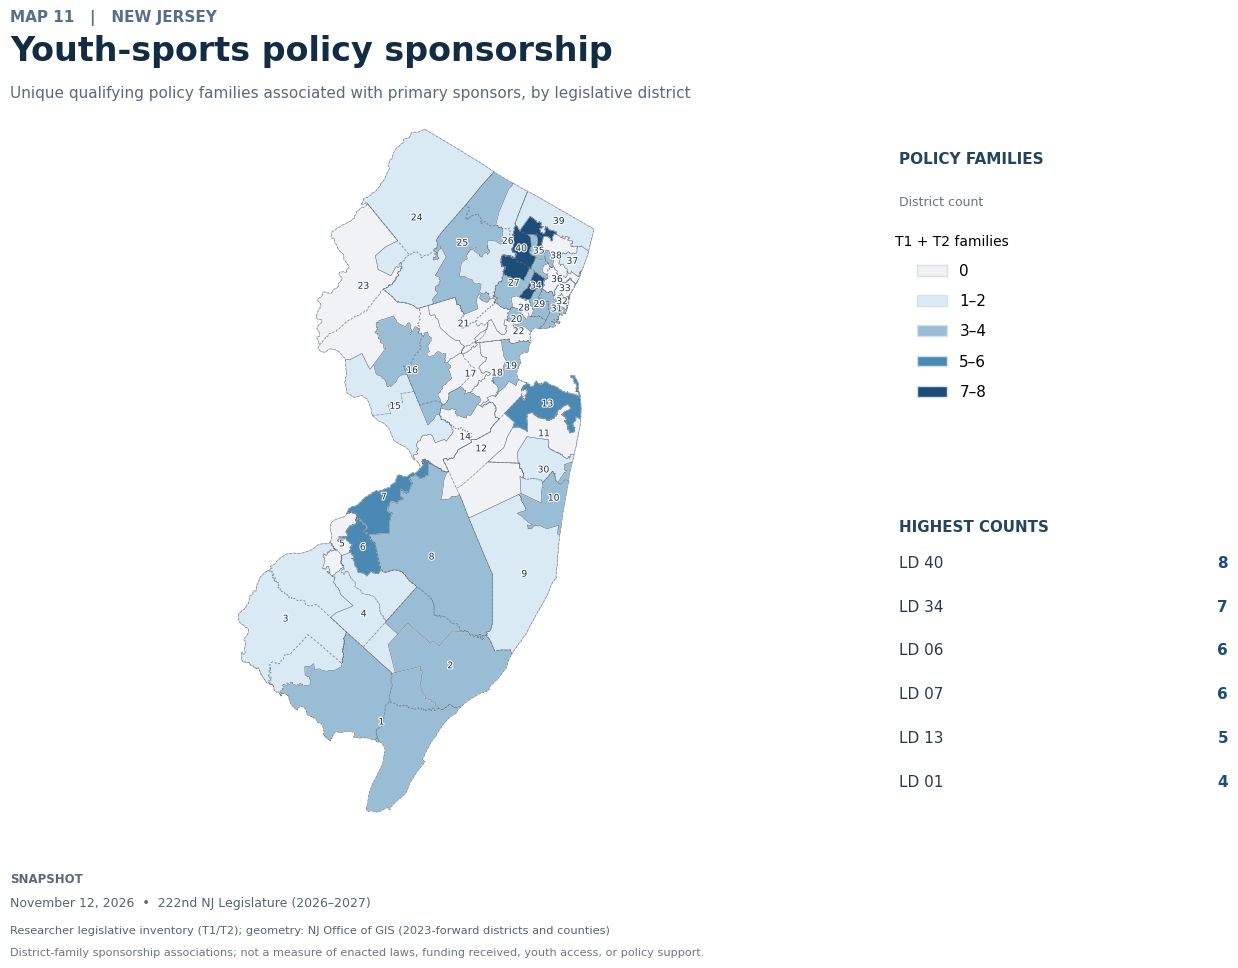

Saved: /content/NJ_Map11_Youth_Sports_Policy_Districts.png and /content/NJ_Map11_Youth_Sports_Policy_Districts.pdf


In [11]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib import patheffects
from pathlib import Path

map_palette = {
    "0": "#F0F2F5",
    "1–2": "#DAEAF4",
    "3–4": "#9ABDD6",
    "5–6": "#4B89B5",
    "7–8": "#1D4D79",
}

def color_group(value):
    n = int(value)
    return "0" if n == 0 else "1–2" if n <= 2 else "3–4" if n <= 4 else "5–6" if n <= 6 else "7–8"

nj_map11["Class"] = nj_map11["Map11_Policy_Family_Count_T1_T2"].map(color_group)
nj_map11["Map_Color"] = nj_map11["Class"].map(map_palette)

fig = plt.figure(figsize=(14, 10.2), facecolor="white")
ax = fig.add_axes([0.045, 0.14, 0.60, 0.73])
ax.set_aspect("equal")
nj_map11.plot(ax=ax, color=nj_map11["Map_Color"], edgecolor="#FFFFFF", linewidth=.48)
if county_boundaries is not None:
    county_boundaries.boundary.plot(ax=ax, color="#697580", linewidth=.5, linestyle=(0, (3, 3)), alpha=.66)
nj_map11.boundary.plot(ax=ax, color="#596A78", linewidth=.32, alpha=.8)

for _, rec in nj_map11.iterrows():
    point = rec.geometry.representative_point()
    ax.text(point.x, point.y, str(int(rec["Legislative_District"])),
            fontsize=6.6, ha="center", va="center", color="#213747", weight="medium",
            path_effects=[patheffects.withStroke(linewidth=1.6, foreground="white", alpha=.95)])

ax.set_axis_off()
ax.margins(x=.045, y=.045)
fig.text(.055,.945,"MAP 11   |   NEW JERSEY", fontsize=11, weight="bold", color="#55708A")
fig.text(.055,.907,"Youth-sports policy sponsorship",fontsize=24,weight="bold",color="#122C44")
fig.text(.055,.870,"Unique qualifying policy families associated with primary sponsors, by legislative district",fontsize=11,color="#5B6A78")

fig.text(.69,.806,"POLICY FAMILIES",fontsize=11,weight="bold",color="#24455F")
fig.text(.69,.765,"District count",fontsize=9,color="#657686")
leg_handles = [Patch(facecolor=map_palette[key],edgecolor="#D7E0E8",label=key) for key in map_palette]
fig.legend(handles=leg_handles,title="T1 + T2 families",loc="upper left",bbox_to_anchor=(.677,.75),ncol=1,frameon=False,fontsize=11,title_fontsize=10,labelspacing=1.0)

leaders=nj_map11.sort_values(["Map11_Policy_Family_Count_T1_T2","Legislative_District"],ascending=[False,True]).head(6)
fig.text(.69,.445,"HIGHEST COUNTS",fontsize=10.8,weight="bold",color="#24455F")
for i, rec in enumerate(leaders.itertuples(index=False)):
    y=.410-i*.043
    fig.text(.69,y,f"LD {int(rec.Legislative_District):02d}",fontsize=11,color="#27394B")
    fig.text(.925,y,f"{int(rec.Map11_Policy_Family_Count_T1_T2)}",fontsize=11,weight="bold",ha="right",color="#1D4D79")

fig.text(.055,.101,"SNAPSHOT",fontsize=8.5,weight="bold",color="#5B6977")
fig.text(.055,.077,"November 12, 2026  •  222nd NJ Legislature (2026–2027)",fontsize=9,color="#526575")
fig.text(.055,.051,"Researcher legislative inventory (T1/T2); geometry: NJ Office of GIS (2023-forward districts and counties)",fontsize=8.2,color="#526575")
fig.text(.055,.029,"District-family sponsorship associations; not a measure of enacted laws, funding received, youth access, or policy support.",fontsize=8.1,color="#697783")

output_png=Path("NJ_Map11_Youth_Sports_Policy_Districts.png")
output_pdf=Path("NJ_Map11_Youth_Sports_Policy_Districts.pdf")
fig.savefig(output_png,dpi=210,facecolor="white")
fig.savefig(output_pdf,facecolor="white")
plt.show()
print("Saved:",output_png.resolve(),"and",output_pdf.resolve())

## 4 · Optional interactive district map (Folium)

Hover over any district to see the combined count and separate T1/T2 categories. The Folium version is *supplemental*; use the static map above as the main PS4 figure. It may require an active connection to load the background tiles.

In [12]:
import folium

hover_fields = ["Legislative_District", "Map11_Policy_Family_Count_T1_T2",
                "T1_Community_Youth_Sports_Count", "T2_K12_Interscholastic_Count"]
view = nj_map11.to_crs(4326)

interactive_map = folium.Map(location=[40.10, -74.57],zoom_start=8,tiles="CartoDB positron",control_scale=True)
folium.GeoJson(
    view[[*hover_fields,"Map_Color","geometry"]].to_json(),
    name="Legislative districts",
    style_function=lambda feature: {
        "fillColor": feature["properties"]["Map_Color"],
        "color": "#44596B", "weight": 0.7, "fillOpacity": 0.81
    },
    highlight_function=lambda feature: {"weight": 2, "color": "#132D48", "fillOpacity": 0.98},
    tooltip=folium.GeoJsonTooltip(
        fields=hover_fields,
        aliases=["Legislative district:","Combined T1+T2:","T1 community sports:","T2 K–12 athletics:"],
        localize=True, sticky=True
    ),
).add_to(interactive_map)
folium.LayerControl().add_to(interactive_map)
interactive_map.save("NJ_Map11_Interactive_Folium.html")
display(interactive_map)

/usr/local/lib/python3.13/dist-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## 5 · Analytical interpretation for PS4

**Descriptive result.** In the November 12, 2026 dataset, 26 of New Jersey's 40 legislative districts are associated with at least one of the 43 qualifying policy families (17 T1 and 26 T2). The district counts sum to **84 sponsor-district–family associations**, **not** 84 distinct families. Legislative District 40 has the highest combined count (8), followed by District 34 (7); Districts 6 and 7 each have 6.

**What the pattern can support.** The map describes the distribution of *primary sponsorship within this classified inventory*. It can help NJYASA identify which districts have legislators already sponsoring youth-sports or school-athletics proposals and which bills warrant closer policy analysis. Separate T1 and T2 counts matter because interscholastic policy should not be presented as directly regulating community youth sports.

**What the pattern cannot support.** A zero is **no qualifying primary-sponsor association in this dataset**, not proof that district legislators oppose youth sports or that no relevant programs exist. The map does not measure enacted law, youth participation, geographic demand, funding, service quality, demographic equity, or legislative causation. Sponsor districts are legislators' constituencies; they are **not necessarily the geographic areas that would receive the policy's benefits**. Inventoried companion bills are de-duplicated within policy families, but families may have sponsors from multiple districts.

**Next before final submission.** Verify official source links and current sponsorship/status, publish the dataset to your GitHub repository, check labels on the produced map, and add it to the cumulative PS4 narrative. An optional NJYASA regional boundary overlay should be added **only** after the final county-to-region assignment is independently confirmed.

In [13]:
# Save the joined 40-district research layer and an audit table for reuse.
output_geojson = "NJ_Map11_Joined_2026_11_12.geojson"
nj_map11.to_crs(4326)[[
    "Legislative_District", "Map11_Policy_Family_Count_T1_T2",
    "T1_Community_Youth_Sports_Count", "T2_K12_Interscholastic_Count",
    "T3_Adjacent_Count_Excluded_From_Map11", "Snapshot_Date", "geometry"
]].to_file(output_geojson, driver="GeoJSON")
print("Saved",output_geojson)

# In Colab, uncomment these lines to download final files:
# from google.colab import files
# for filename in ["NJ_Map11_Youth_Sports_Policy_Districts.png",
#                  "NJ_Map11_Youth_Sports_Policy_Districts.pdf",
#                  "NJ_Map11_Interactive_Folium.html", output_geojson]:
#     files.download(filename)

Saved NJ_Map11_Joined_2026_11_12.geojson
